
# **<center><font style="color:rgb(100,109,254)">Human Action Classification in Videos with CNN-LSTM using Keras</font> </center>**


<img src='https://debuggercafe.com/wp-content/uploads/2023/05/human-action-recongition-2d-cnn-drinking.gif'></center>





## **<font style="color:rgb(134,19,348)"> Outline </font>**

- **`Step 1:` Visualize the Data with its Labels**

- **`Step 2:` Preprocess the Dataset**

- **`Step 3:` Split the Data into Train and Test Set**

- **`Step 4:` Your Model**

    - **`Step 4.1:` Construct the Model**
    
    - **`Step 4.2:` Compile & Train the Model**
    
    - **`Step 4.3:` Plot Model’s Loss & Accuracy Curves**
    
- **`Step 5:` Test the Model on Test set videos**

### **<font style="color:rgb(134,19,348)"> Import the Libraries</font>**

Start by installing and importing the required libraries.

In [4]:
# Import the required libraries.
import os
import cv2
import math
import random
import numpy as np
import datetime as dt
import tensorflow as tf
from collections import deque
import matplotlib.pyplot as plt
import zipfile
import re

%matplotlib inline

from sklearn.model_selection import train_test_split

from keras.layers import *
from keras.models import Sequential
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import plot_model
from keras.models import Model
from keras.optimizers import Adam

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import classification_report



Install TensorFlow and Cuda:

Run in terminal: pip install "tensorflow[and-cuda]"

Set `Numpy`, `Python`, and `Tensorflow` seeds

In [5]:
seed_constant = 27 #choose a number according to your choice
np.random.seed(seed_constant)
random.seed(seed_constant)
tf.random.set_seed(seed_constant)

Here we Download the video Data set from the given site.

In [6]:
#Load data
# In original code, here they download dataset from some website
# This website did not work for me, so I downloaded the dataset from Kaggle (https://www.kaggle.com/datasets/pypiahmad/realistic-action-recognition-ucf50)
# And then unzipped it

with zipfile.ZipFile("UCF50.zip", "r") as zip_ref:
    zip_ref.extractall("UCF50_data")

## **<font style="color:rgb(134,19,348)">Step 1: Visualize the Data with its Labels</font>**

In the first step, you have to visualize the data along with labels to get an idea about what you will be dealing with. you will be using the [UCF50 - Action Recognition Dataset](https://www.crcv.ucf.edu/data/UCF50.php), consisting of realistic videos taken from youtube which differentiates this data set from most of the other available action recognition data sets as they are not realistic and are staged by actors. The Dataset contains:

*   **`50`** Action Categories

*   **`25`** Groups of Videos per Action Category

*   **`133`** Average Videos per Action Category

*   **`199`** Average Number of Frames per Video

*   **`320`** Average Frames Width per Video

*   **`240`** Average Frames Height per Video

*   **`26`** Average Frames Per Seconds per Video

For visualization, You should pick `12` random categories from the dataset and a random video from each selected category and visualize the first frame of the selected videos with their associated labels written. This way we’ll be able to visualize a subset ( `12` random videos ) of the dataset.

Basketball Total videos:  137
Lunges Total videos:  141
Billiards Total videos:  150
SalsaSpin Total videos:  133
PommelHorse Total videos:  123
Rowing Total videos:  137
Drumming Total videos:  161
BreastStroke Total videos:  101
HighJump Total videos:  123
VolleyballSpiking Total videos:  116
Swing Total videos:  137
BenchPress Total videos:  160


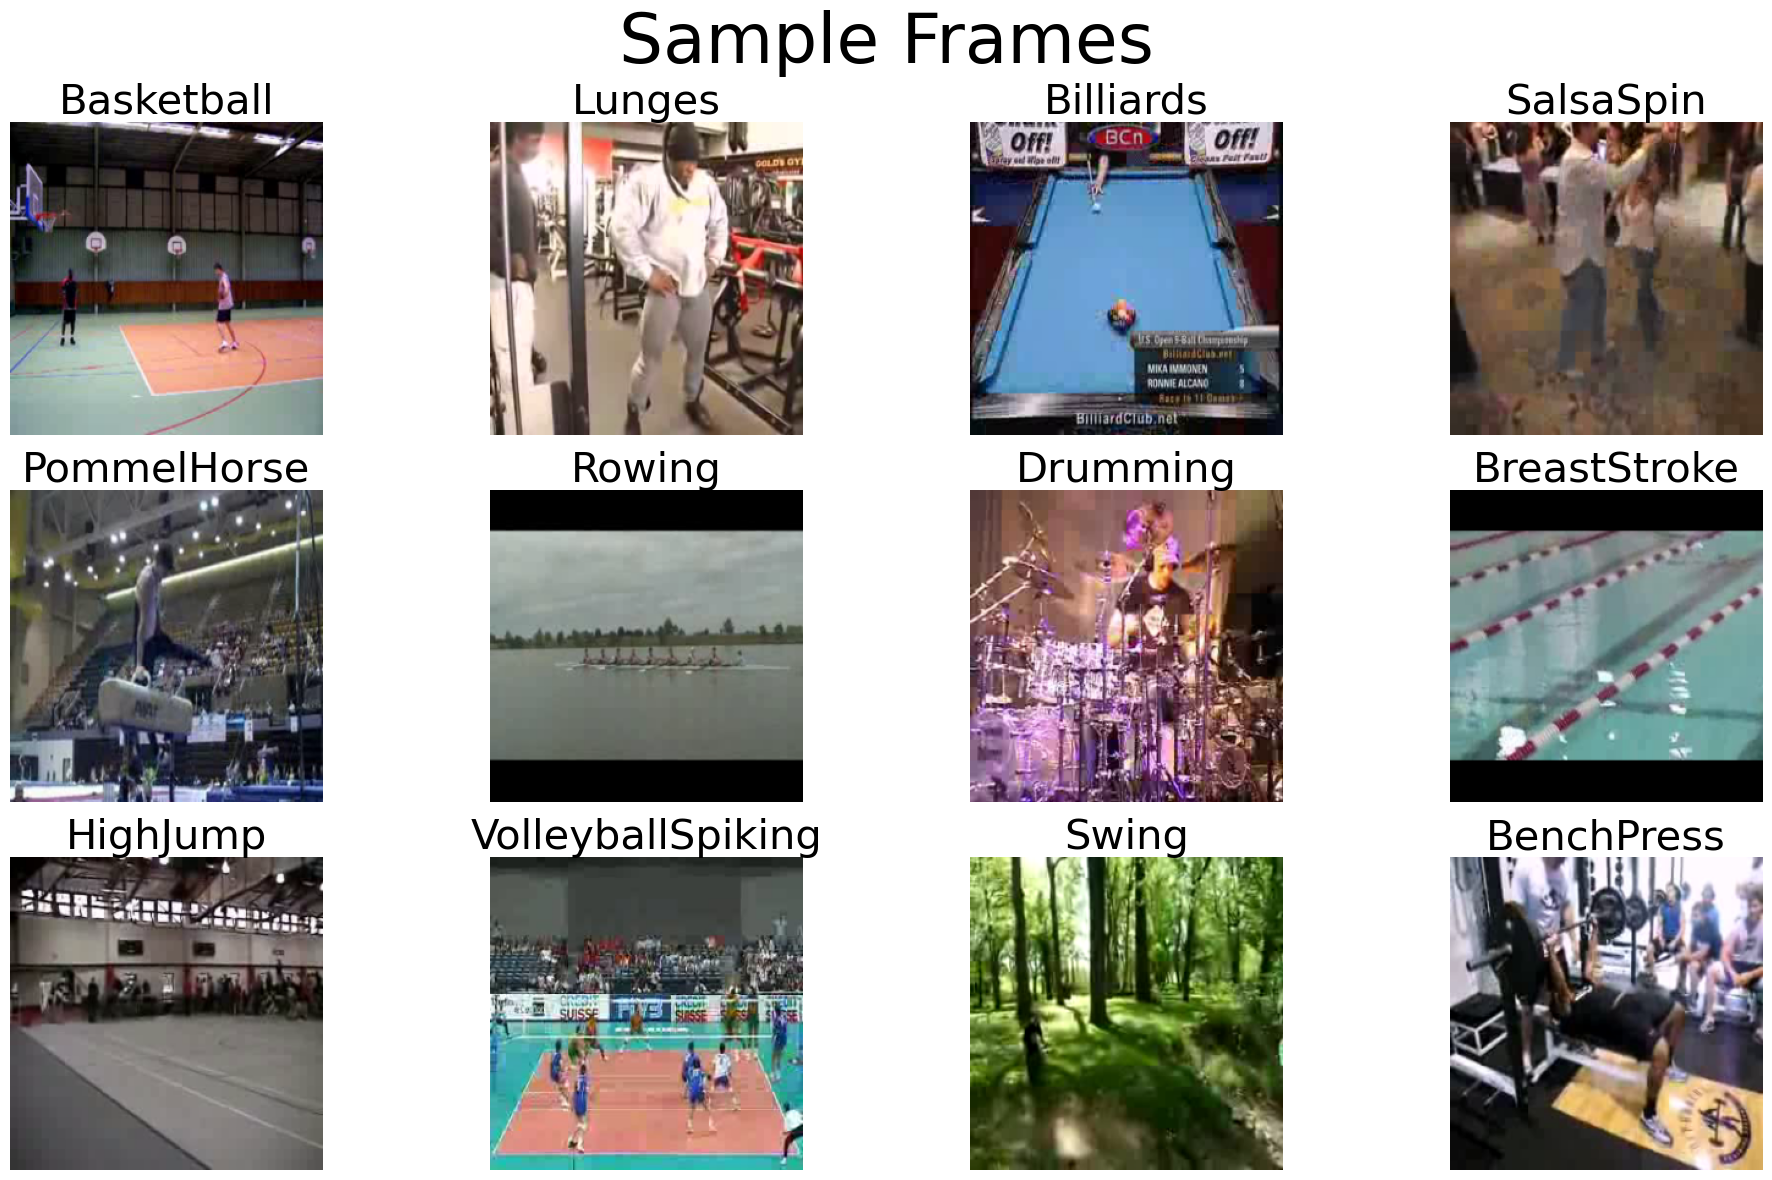

In [7]:
# Path to UNZIPED data
# Here is path to my data, change it to yours if you want to test this code.
data_path = "/home/dima/Desktop/AI-submissions/AI-submissions/AI-course/Final_Project/UCF50_data"

# 12 Classes because this is required in assignment to show previews
# Later, I will use only 6 classes for less computations.
classes = [
    "Basketball",
    "Lunges",
    "Billiards",
    "SalsaSpin",
    "PommelHorse",
    "Rowing",
    "Drumming",
    "BreastStroke",
    "HighJump",
    "VolleyballSpiking",
    "Swing",
    "BenchPress"
]

# Total videos per class
for cls in classes:
    print(f"{cls} Total videos: ", len(os.listdir(os.path.join(data_path,cls))))

# This shows examples of videos in folders
def show_sample(classes, data_path):
    # Plot
    fig, axes = plt.subplots(3,4,figsize=(20,12))
    axes = axes.flatten()


    for i, cls in enumerate(classes):
        # Path to video
        video_path = os.path.join(data_path, cls, os.listdir(os.path.join(data_path,cls))[0])

        # Capture the video
        cap = cv2.VideoCapture(video_path) 

        # ret is a boolean that tells if the frame is available. Frame is frame of the video.
        ret, frame = cap.read()

        # Close the video capture
        cap.release()

        # If frame exists, set it to the plot
        if ret:
            frame = cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame,(256,256))
            axes[i].imshow(frame)
            axes[i].set_title(cls, fontsize = 30)
        axes[i].axis('off')

    # plot the sample frames
    plt.suptitle("Sample Frames",fontsize = 50)
    plt.tight_layout()
    plt.show()

show_sample(classes, data_path)

        

## **<font style="color:rgb(134,19,348)">Step 2: Preprocess the Dataset</font>**

Next, You perform some preprocessing on the dataset. First, You have to read the video files from the dataset and resize the frames of the videos to a fixed width and height, to reduce the computations and normalized the data to range `[0-1]` by dividing the pixel values with `255`, which makes convergence faster while training the network.

*But first, let's initialize some constants.*

In [8]:
# Specify the height and width to which each video frame will be resized in our dataset.
IMAGE_HEIGHT , IMAGE_WIDTH = 64, 64

# Specify the number of frames of a video that will be fed to the model as one sequence.
SEQUENCE_LENGTH = 30

# the directory containing the UCF50 dataset.
DATASET_DIR = "/home/dima/Desktop/AI-submission/Final_Project/UCF50_data"   # Change this to path where it unziped files. Here I used mine path

# Specify the list containing the names of the classes used for training. Feel free to choose any set of classes.
CLASSES_LIST = ["Basketball","Lunges", "Billiards","SalsaSpin","PommelHorse","Rowing"] # I used 6 classes for less computations

NUM_CLASSES = len(CLASSES_LIST)

**Note:** *The **`IMAGE_HEIGHT`**, **`IMAGE_WIDTH`** and **`SEQUENCE_LENGTH`** constants can be increased for better results, although increasing the sequence length is only effective to a certain point, and increasing the values will result in the process being more computationally expensive.*

### **<font style="color:rgb(134,19,348)">Create a Function to Extract, Resize & Normalize Frames</font>**

Create a function **`frames_extraction()`** that will create a list containing the resized and normalized frames of a video whose path is passed to it as an argument. The function will read the video file frame by frame, until the sequence length of frames are collected.

In [9]:
def frames_extraction(video_path):
    '''
    This function will extract the required frames from a video after resizing and normalizing them.
    Args:
        video_path: The path of the video in the disk, whose frames are to be extracted.
    Returns:
        frames_list: A list containing the resized and normalized frames of the video.
    '''

    # List of frames
    frames_list = []

    # Video capture
    video_reader = cv2.VideoCapture(video_path)

    # How many frames in total
    frame_count = int(video_reader.get(cv2.CAP_PROP_FRAME_COUNT))

    # How many frames will be skipped. If frame_count = 600, then skip_frames_window will be 600/20 = 30. So, we skip 30 frames and take 31th frame etc.
    skip_frames_window = max(int(frame_count / SEQUENCE_LENGTH), 1)

    # Here we get maximum of 20 frames of one video
    for frame_counter in range(SEQUENCE_LENGTH):

        # We get only frames that is current frame_counter multiplied by skip_frames_window
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, frame_counter * skip_frames_window)
        
        ret, frame = video_reader.read()

        if not ret:
            print("Ret error")
            break

        # Resize to specific (fixed) size
        frame_resize = cv2.resize(frame,(IMAGE_HEIGHT, IMAGE_WIDTH))

        # We then normalize the frame so that every pixel value is between 0 and 1.
        normalized_frame = frame_resize / 255

        # Add frames to list
        frames_list.append(normalized_frame)

    #Stop reading video
    video_reader.release()

    return frames_list

### **<font style="color:rgb(134,19,348)">Create a Function for Dataset Creation</font>**

Create a function **`create_dataset()`** that will iterate through all the classes specified in the **`CLASSES_LIST`** constant and will call the function  **`frame_extraction()`** on every video file of the selected classes and return the frames (**`features`**), class index ( **`labels`**), and video file path (**`video_files_paths`**).

In [10]:
def create_dataset():
    '''
    This function will extract the data of the selected classes and create the required dataset.
    Returns:
        features:          A list containing the extracted frames of the videos.
        labels:            A list containing the indexes of the classes associated with the videos.
        video_files_paths: A list containing the paths of the videos in the disk.
    '''
    # features, labels and paths to video files
    features = []
    labels = []
    video_files_paths = []
    
    for class_index, class_name in enumerate(CLASSES_LIST):
        
        # Add all videos to list
        videos_list = os.listdir(os.path.join(data_path,class_name))

        print("Processing class:", class_name)
        for video_name in videos_list:

            # Path to single video file
            video_file_path = os.path.join(data_path,   class_name, video_name)

            # This adds to list frames from one video
            frames = frames_extraction(video_file_path)

            # When we get 20 or 30 frames (depends on SEQUENCE_LENGTH), add them to features and add label of class (e.g "basketball") to labels list and add path to video
            if len(frames) == SEQUENCE_LENGTH:
                features.append(frames)
                labels.append(class_index)
                video_files_paths.append(video_file_path)

    # We need to convert them to np array
    features = np.asarray(features)
    labels = np.asarray(labels)

    return features, labels, video_files_paths

Utilize the function **`create_dataset()`** created above to extract the data of the selected classes and create the required dataset.

In [11]:
# Create the dataset.
features, labels, video_files_paths = create_dataset()

Processing class: Basketball
Processing class: Lunges
Processing class: Billiards
Processing class: SalsaSpin
Processing class: PommelHorse
Processing class: Rowing


`features.shape` and `labels`.

In [12]:
print(features.shape)
print(labels)
print(labels.shape)

(821, 30, 64, 64, 3)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3

Convert `labels` (class indexes) into one-hot encoded vectors.

In [13]:
# Using Keras's to_categorical method to convert labels into one-hot-encoded vectors
one_hot_encoded_labels = to_categorical(labels)

print(one_hot_encoded_labels)
print(labels.shape)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]
(821,)


## **<font style="color:rgb(134,19,348)">Step 3: Split the Data into Train and Test Set</font>**

As of now, you should have the required **`features`** (a NumPy array containing all the extracted frames of the videos) and **`one_hot_encoded_labels`** (also a Numpy array containing all class labels in one hot encoded format). You will split your data to create training and testing sets.
you should store the data into the four variables: `features_train, features_test, labels_train, labels_test`

Hint: shuffle the dataset before the split to avoid any bias and get splits representing the overall distribution of the data.

In [14]:
print("Splitting start")

train_idx, val_idx, test_idx = [], [], []

for i, path in enumerate(video_files_paths):
    # v_Basketball_g01_c02.avi -> group number 1
    group = int(re.search(r"_g(\d+)_", os.path.basename(path)).group(1))

    if group <= 16:
        train_idx.append(i)
    elif group <= 20:
        val_idx.append(i)
    else:
        test_idx.append(i)

features_train, labels_train = features[train_idx], one_hot_encoded_labels[train_idx]
features_val,   labels_val   = features[val_idx],   one_hot_encoded_labels[val_idx]
features_test,  labels_test  = features[test_idx],  one_hot_encoded_labels[test_idx]

print("Splitting end")
print("train:", features_train.shape, "val:", features_val.shape, "test:", features_test.shape)

Splitting start
Splitting end
train: (535, 30, 64, 64, 3) val: (131, 30, 64, 64, 3) test: (155, 30, 64, 64, 3)


## **<font style="color:rgb(134,19,348)">Step 4: Implement the ConvLSTM Approach</font>**
Create a sequential model.

Hint:
- use keras ConvLSTM2D layers to create a model that takes the power of CNN+LSTM in one layer.
- You can use recurrent dropout for the ConvLSTM2D
- You can utalize the power of timedistributed layers, study how it helps in processing sequential data?
- Use Maxpooling2D and 3D layers, study why and where?
- You can also use Conv2D and LSTM to form your model.


The given images shows how does a ConvLSTM handles data.

<center>
<img src="https://drive.google.com/uc?export=view&id=1KHN_JFWJoJi1xQj_bRdxy2QgevGOH1qP" width= 500px>
</center>


The ConvLSTM will take a 3-dimensional input `(width, height, num_of_channels)` whereas a simple LSTM only takes in 1-dimensional input hence an LSTM is incompatible for modeling Spatio-temporal data on its own.

You can read the paper [**Convolutional LSTM Network: A Machine Learning Approach for Precipitation Nowcasting**](https://arxiv.org/abs/1506.04214v1) by **Xingjian Shi** (NIPS 2015), to learn more about this architecture.


### **<font style="color:rgb(134,19,348)">Step 4.1: Construct the Model</font>**


To construct the model, we will use Keras [**`ConvLSTM2D`**](https://keras.io/api/layers/recurrent_layers/conv_lstm2d) recurrent layers. The **`ConvLSTM2D`** layer also takes in the number of filters and kernel size required for applying the convolutional operations. The output of the layers is flattened in the end and is fed to the **`Dense`** layer with softmax activation which outputs the probability of each action category.

We will also use **`MaxPooling3D`** layers to reduce the dimensions of the frames and avoid unnecessary computations and **`Dropout`** layers to prevent [overfitting](https://en.wikipedia.org/wiki/Overfitting) the model on the data. The architecture is a simple one and has a small number of trainable parameters. This is because we are only dealing with a small subset of the dataset which does not require a large-scale model.

In [15]:
# I put this here (instead of putting locally inside of a model) because we will need later to access it in cell where we do .fit()
early_stop = EarlyStopping(
        monitor="val_accuracy",
        patience=12,
        restore_best_weights=True,
    )

reduce_lr = ReduceLROnPlateau(
    monitor="val_accuracy", 
    factor=0.5, 
    patience=6, 
    min_lr=1e-6)


def your_model():

    # Frames and their properties
    frames = SEQUENCE_LENGTH
    height = IMAGE_HEIGHT
    width = IMAGE_WIDTH
    channels = 3 #RGB

    # number of classes (6 in my case: "Basketball, Lunges, Billiards,SalsaSpin, PommelHorse, Rowing)
    num_classes = NUM_CLASSES

    model = Sequential()


    # https://medium.com/neuronio/an-introduction-to-convlstm-55c9025563a7
    # I followed this guide to make this
    
    # Input
    model.add(Input(shape=(frames, height, width, channels)))

    # Conv layer
    model.add(ConvLSTM2D(filters=20, kernel_size=(3,3), padding="same", recurrent_activation="hard_sigmoid", activation="tanh", return_sequences=True))

    # Batch Normalizatin
    model.add(BatchNormalization())

    # Pooling
    model.add(MaxPooling3D(pool_size=(1,2,2), padding='same'))

    # Conv
    model.add(ConvLSTM2D(filters=20, kernel_size=(3,3), padding="same", recurrent_activation="hard_sigmoid", activation="tanh", return_sequences=False))

    # Normalization
    model.add(BatchNormalization())

    # Pooling
    model.add(GlobalAveragePooling2D())
    
    # Dropout
    model.add(Dropout(0.2))

    # For output
    model.add(Dense(num_classes, activation="softmax"))


    return model

Now we will utilize the function **`your_model()`** created above, to construct the required `convlstm_model`.

In [16]:
# Construct the required convlstm model.
convlstm_model = your_model()

# Display the success message.
print("Model Created Successfully!")
print(convlstm_model.summary())

I0000 00:00:1795006156.044276  498708 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4504 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2070 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Model Created Successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d (ConvLSTM2D)        │ (None, 30, 64, 64, 20) │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 64, 64, 20) │            80 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 30, 32, 32, 20) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_1 (ConvLSTM2D)      │ (None, 32, 32, 20)     │        28,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 20)     │            80 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 20)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           126 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,806 (178.93 KB)

 Trainable params: 45,726 (178.62 KB)

 Non-trainable params: 80 (320.00 B)

None


#### **<font style="color:rgb(134,19,348)">Check Model’s Structure:</font>**

You can use the **`plot_model()`** function, to check the structure of the constructed model, this is helpful while constructing a complex network and making that the network is created correctly.

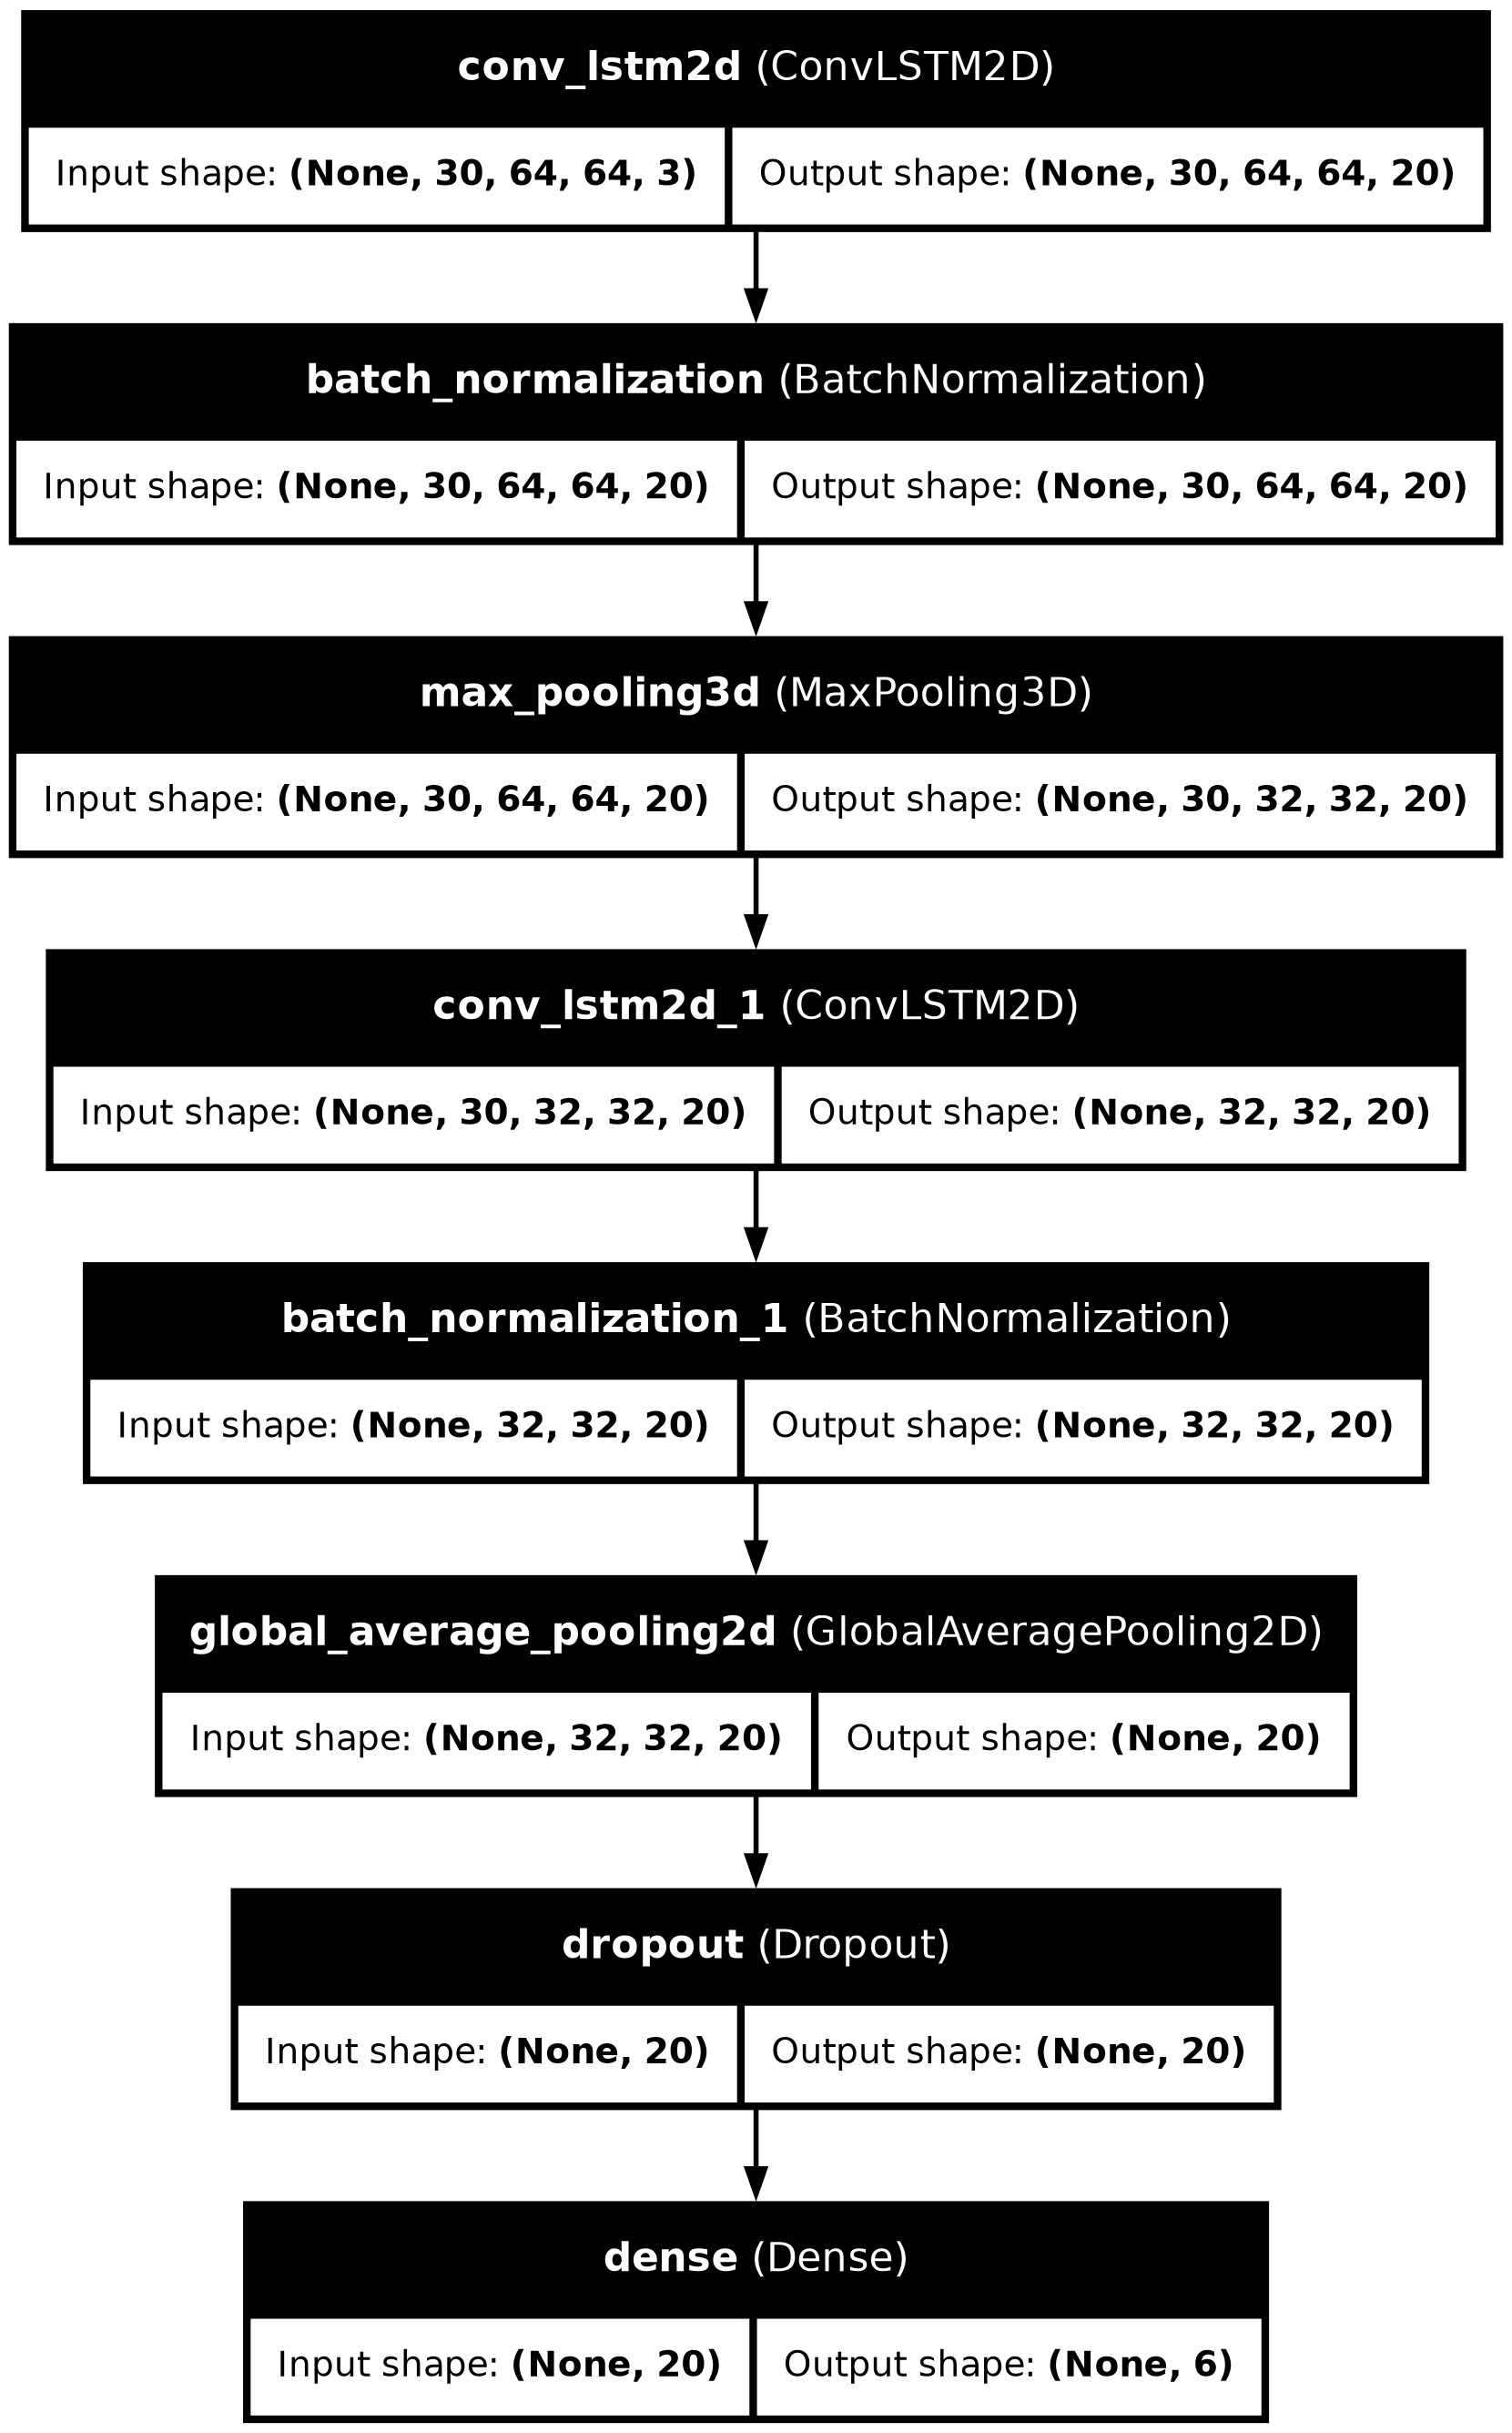

In [17]:
# Plot the structure of the contructed model.
plot_model(convlstm_model, to_file = 'convlstm_model_structure_plot.png', show_shapes = True, show_layer_names = True)

### **<font style="color:rgb(134,19,348)">Step 4.2: Compile & Train the Model</font>**

Next, You can add callbacks for early stopping to prevent [overfitting](https://en.wikipedia.org/wiki/Overfitting) and start the training after compiling the model.

You can use `batch_size, validation_split` of your choice.

Train the model and save the model and its training history to plot it after completion.

Hint: `batch_size` for large data should be smaller to prevent you system from overload.

In [18]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))
# Compile
convlstm_model.compile(optimizer=Adam(learning_rate=0.001), loss="categorical_crossentropy", metrics=['accuracy'])


# Train 
history = convlstm_model.fit(features_train, labels_train, epochs=60, validation_data =(features_val, labels_val), batch_size=16, callbacks=[early_stop, reduce_lr])



[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1795006157.236299  498708 cpu_allocator_impl.cc:174] Allocation of 788889600 exceeds 10% of free system memory.
W0000 00:00:1795006157.633982  498708 cpu_allocator_impl.cc:174] Allocation of 788889600 exceeds 10% of free system memory.


Epoch 1/60


I0000 00:00:1795006159.611592  498708 service.cc:154] XLA service 0x560c85df7790 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795006159.611605  498708 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 2070 SUPER, Compute Capability 7.5 (Driver: 13.4.0[615.78.8]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795006159.704455  498708 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795006160.429492  498708 cuda_dnn.cc:442] Loaded cuDNN version 92801


 1/34 ━━━━━━━━━━━━━━━━━━━━ 2:26 4s/step - accuracy: 0.1250 - loss: 1.8559

I0000 00:00:1795006162.181831  498708 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


34/34 ━━━━━━━━━━━━━━━━━━━━ 16s 353ms/step - accuracy: 0.4879 - loss: 1.3319 - val_accuracy: 0.2061 - val_loss: 1.7760 - learning_rate: 0.0010
Epoch 2/60
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - accuracy: 0.5794 - loss: 1.0901 - val_accuracy: 0.1679 - val_loss: 1.7746 - learning_rate: 0.0010
Epoch 3/60
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - accuracy: 0.6187 - loss: 1.0247 - val_accuracy: 0.2061 - val_loss: 1.8378 - learning_rate: 0.0010
Epoch 4/60
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 182ms/step - accuracy: 0.6692 - loss: 0.9359 - val_accuracy: 0.1756 - val_loss: 1.9375 - learning_rate: 0.0010
Epoch 5/60
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - accuracy: 0.7065 - loss: 0.8963 - val_accuracy: 0.3130 - val_loss: 1.6184 - learning_rate: 0.0010
Epoch 6/60
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - accuracy: 0.7121 - loss: 0.8176 - val_accuracy: 0.2824 - val_loss: 1.6897 - learning_rate: 0.0010
Epoch 7/60
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - accuracy: 0.7495 - loss: 0.7391 - val_accura

### **<font style="color:rgb(134,19,348)">Step 4.3: Plot Model’s Loss & Accuracy Curves</font>**


Visualize the training and validation metrics.

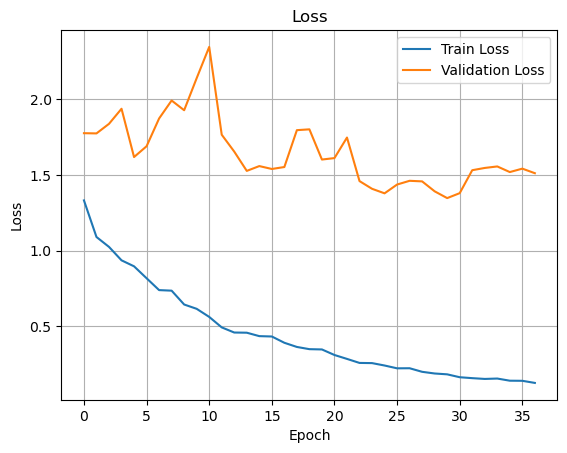

In [27]:
# Visualize the training and validation loss metrices.
plt.plot(history.history['loss'], label="Train Loss")
plt.plot(history.history['val_loss'], label= "Validation Loss")
plt.title("Loss")
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()



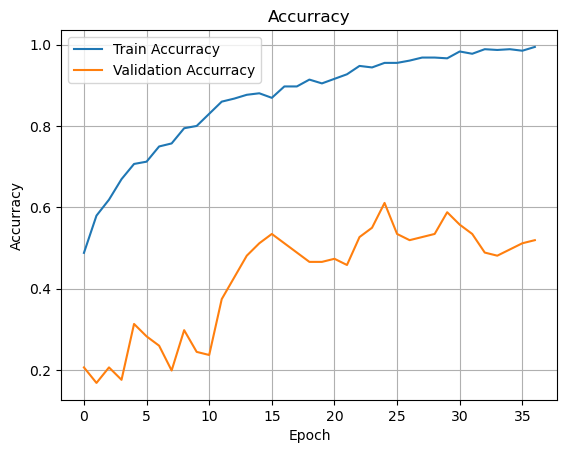

In [20]:
# Visualize the training and validation accuracy metrices.
plt.plot(history.history['accuracy'], label="Train Accurracy")
plt.plot(history.history['val_accuracy'], label= "Validation Accurracy")
plt.title("Accurracy")
plt.xlabel('Epoch')
plt.ylabel('Accurracy')
plt.legend()
plt.grid(True)
plt.show()



#### **<font style="color:rgb(134,19,348)">Evaluate the Trained Model</font>**

Evaluate the model on the test set.

`features_test, labels_test`, print the accuracy of your model.

plot the following:
 - confusion matrix
 - precision and recall curves
 - t-SNE visualization (optional)

 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8125 - loss: 0.6227

W0000 00:00:1795006406.045008  498708 cpu_allocator_impl.cc:174] Allocation of 228556800 exceeds 10% of free system memory.
W0000 00:00:1795006406.170640  498708 cpu_allocator_impl.cc:174] Allocation of 228556800 exceeds 10% of free system memory.


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 188ms/step - accuracy: 0.7355 - loss: 0.6899
Test loss:  0.689854621887207
Test accuracy:  0.7354838848114014


W0000 00:00:1795006408.162825  498708 cpu_allocator_impl.cc:174] Allocation of 228556800 exceeds 10% of free system memory.


5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 474ms/step
Predicted:  [0 0 5 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 3 3 0 1 0 5 5 0 0 0 0 2 2 1 2 2
 0 0 0 1 3 1 1 1 1 1 4 0 0 0 1 0 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 1 1 1 1 1 3 3 3 3 1 1 1 1 1 3 3 3 3 3 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 1 5 1 1 5 1 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5]
Actual, real value:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5]
Labels test:  [[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0

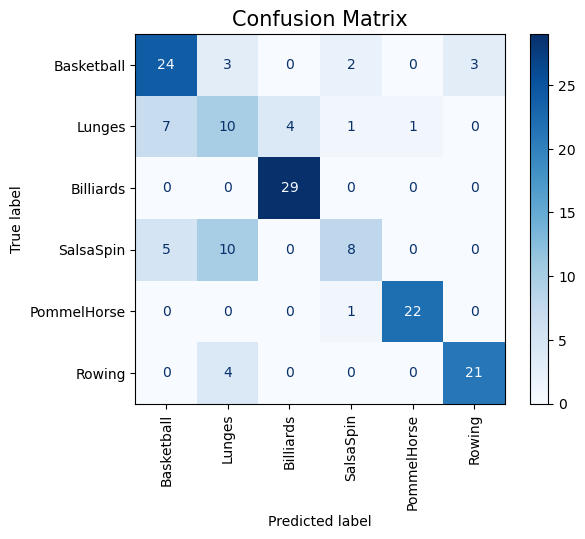

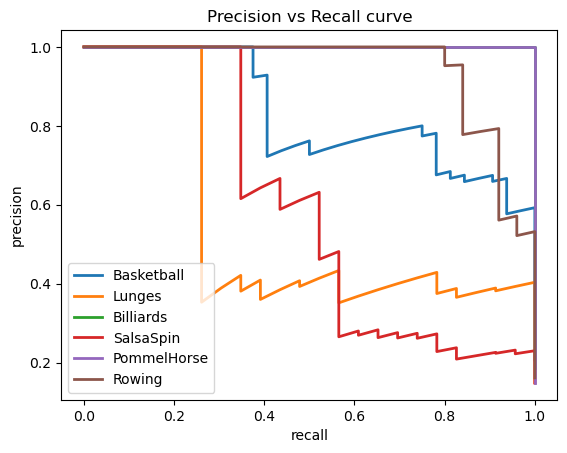

In [21]:
# Evaluationg
test_loss, test_accuracy = convlstm_model.evaluate(
    features_test, labels_test, batch_size=16
)

print("Test loss: ", test_loss)
print("Test accuracy: ", test_accuracy)



# Matrix & Precission and Recall curves. I did not do t-SNE visualization.
# Predict
predictions = convlstm_model.predict(features_test)

# Convert probabilities to classes
label_pred = np.argmax(predictions, axis=1)

# Actual, true values
label_true = np.argmax(labels_test, axis=1)

print("Predicted: ",  label_pred)
print("Actual, real value: ", label_true)

print("Labels test: ", labels_test)

# Confusion matrix
cm = confusion_matrix(label_true, label_pred)
conf_matrix = ConfusionMatrixDisplay(cm, display_labels=CLASSES_LIST)
conf_matrix.plot(cmap="Blues")
plt.title("Confusion Matrix", fontsize=15)
plt.xticks(rotation=90)
plt.show()


# Precission and recall curve
# I first found the precision_recall_curve but in documentation it says that it is used for binary only and I got multiclass error
# Thanks to random person on stackoverflow https://stackoverflow.com/questions/56090541/how-to-plot-precision-and-recall-of-multiclass-classifier
precision = dict()
recall = dict()

for class_index, class_name in enumerate(CLASSES_LIST):
    precision[class_index], recall[class_index], _ = precision_recall_curve(labels_test[:, class_index], predictions[:, class_index])
    plt.plot(recall[class_index], precision[class_index], lw=2, label=class_name)

plt.xlabel("recall")
plt.ylabel("precision")
plt.legend(loc="best")
plt.title("Precision vs Recall curve")
plt.show()


### **<font style="color:rgb(134,19,348)">Create a Function To Perform Action Recognition on Videos</font>**

Here is a function **`predict_on_video()`** that will simply read a video frame by frame from the path passed in as an argument and will perform action recognition on video and save the results.

In [22]:
def predict_on_video(video_file_path, output_file_path, SEQUENCE_LENGTH):
    '''
    This function will perform action recognition on a video using the LRCN model.
    Args:
    video_file_path:  The path of the video stored in the disk on which the action recognition is to be performed.
    output_file_path: The path where the ouput video with the predicted action being performed overlayed will be stored.
    SEQUENCE_LENGTH:  The fixed number of frames of a video that can be passed to the model as one sequence.
    '''

    # Initialize the VideoCapture object to read from the video file.
    video_reader = cv2.VideoCapture(video_file_path)

    # Get the width and height of the video.
    original_video_width = int(video_reader.get(cv2.CAP_PROP_FRAME_WIDTH))
    original_video_height = int(video_reader.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Initialize the VideoWriter Object to store the output video in the disk.
    video_writer = cv2.VideoWriter(output_file_path, cv2.VideoWriter_fourcc('M', 'P', '4', 'V'),
                                   video_reader.get(cv2.CAP_PROP_FPS), (original_video_width, original_video_height))

    # Declare a queue to store video frames.
    frames_queue = deque(maxlen = SEQUENCE_LENGTH)

    # Initialize a variable to store the predicted action being performed in the video.
    predicted_class_name = ''

    # Iterate until the video is accessed successfully.
    while video_reader.isOpened():

        # Read the frame.
        ok, frame = video_reader.read()

        # Check if frame is not read properly then break the loop.
        if not ok:
            break

        # Resize the Frame to fixed Dimensions.
        resized_frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))

        # Normalize the resized frame by dividing it with 255 so that each pixel value then lies between 0 and 1.
        normalized_frame = resized_frame / 255

        # Appending the pre-processed frame into the frames list.
        frames_queue.append(normalized_frame)

        # Check if the number of frames in the queue are equal to the fixed sequence length.
        if len(frames_queue) == SEQUENCE_LENGTH:

            # Pass the normalized frames to the model and get the predicted probabilities.
            predicted_labels_probabilities = convlstm_model.predict(np.expand_dims(frames_queue, axis = 0))[0]

            # Get the index of class with highest probability.
            predicted_label = np.argmax(predicted_labels_probabilities)

            # Get the class name using the retrieved index.
            predicted_class_name = CLASSES_LIST[predicted_label]

        # Write predicted class name on top of the frame.
        cv2.putText(frame, predicted_class_name, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

        # Write The frame into the disk using the VideoWriter Object.
        video_writer.write(frame)

    # Release the VideoCapture and VideoWriter objects.
    video_reader.release()
    video_writer.release()

### **<font style="color:rgb(134,19,348)">Perform Action Recognition on the Test Video</font>**

You can utilize the function **`predict_on_video()`** created above to perform action recognition on the test video and display the output video with the predicted action overlayed on it.

In [23]:
# Construct the output video path.
output_video_file_path = '/home/dima/Desktop/University/AI-course/output_video.mp4'
# Perform Action Recognition on the Test Video.
predict_on_video("/home/dima/Desktop/University/AI-course/UCF50_data/Basketball/v_Basketball_g02_c06.avi", output_video_file_path, SEQUENCE_LENGTH)



### **<font style="color:rgb(134,19,348)">Create a Function To Perform a Single Prediction on Videos</font>**


Here is a function that will perform a single prediction for the complete videos. it will extract evenly distributed **N** **`(SEQUENCE_LENGTH)`** frames from the entire video and pass them to the `your` model. This approach is really useful when you are working with videos containing only one activity as it saves unnecessary computations and time in that scenario.  

In [24]:
def predict_single_action(video_file_path, SEQUENCE_LENGTH):
    '''
    This function will perform single action recognition prediction on a video using the LRCN model.
    Args:
    video_file_path:  The path of the video stored in the disk on which the action recognition is to be performed.
    SEQUENCE_LENGTH:  The fixed number of frames of a video that can be passed to the model as one sequence.
    '''
    # Initialize the VideoCapture object to read from the video file.
    video_reader = cv2.VideoCapture(video_file_path)

    # Get the width and height of the video.
    original_video_width = int(video_reader.get(cv2.CAP_PROP_FRAME_WIDTH))
    original_video_height = int(video_reader.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Declare a list to store video frames we will extract.
    frames_list = []

    # Initialize a variable to store the predicted action being performed in the video.
    predicted_class_name = ''

    # Get the number of frames in the video.
    video_frames_count = int(video_reader.get(cv2.CAP_PROP_FRAME_COUNT))

    # Calculate the interval after which frames will be added to the list.
    skip_frames_window = max(int(video_frames_count/SEQUENCE_LENGTH),1)

    # Iterating the number of times equal to the fixed length of sequence.
    for frame_counter in range(SEQUENCE_LENGTH):

        # Set the current frame position of the video.
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, frame_counter * skip_frames_window)

        # Read a frame.
        success, frame = video_reader.read()

        # Check if frame is not read properly then break the loop.
        if not success:
            break

        # Resize the Frame to fixed Dimensions.
        resized_frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))

        # Normalize the resized frame by dividing it with 255 so that each pixel value then lies between 0 and 1.
        normalized_frame = resized_frame / 255

        # Appending the pre-processed frame into the frames list
        frames_list.append(normalized_frame)

    # Passing the  pre-processed frames to the model and get the predicted probabilities.
    predicted_labels_probabilities = convlstm_model.predict(np.expand_dims(frames_list, axis = 0))[0]

    # Get the index of class with highest probability.
    predicted_label = np.argmax(predicted_labels_probabilities)

    # Get the class name using the retrieved index.
    predicted_class_name = CLASSES_LIST[predicted_label]

    # Display the predicted action along with the prediction confidence.
    print(f'Action Predicted: {predicted_class_name}\nConfidence: {predicted_labels_probabilities[predicted_label]}')

    # Release the VideoCapture object.
    video_reader.release()

### **<font style="color:rgb(134,19,348)">Perform Single Prediction on a Test Video</font>**

Now we will utilize the function **`predict_single_action()`** created above to perform a single prediction on a complete youtube test video that we will download using the function **`download_youtube_videos()`**, we had created above.

In [25]:
# For some reason the original codefile talks about download_youtube_videos(), but here was no any such function? We anyways do not need it.

# Construct the output video path.
output_video_file_path = '/home/dima/Desktop/University/AI-course/output_video2.mp4'
# Perform Action Recognition on the Test Video.
predict_single_action("/home/dima/Desktop/AI-submissions/AI-submissions/AI-course/Final_Project/UCF50_data/Basketball/v_Basketball_g25_c04.avi", SEQUENCE_LENGTH)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Action Predicted: Rowing
Confidence: 0.39126503467559814


Classification Report:

In [26]:
print(classification_report(
    label_true, label_pred,
    labels=range(len(CLASSES_LIST)),
    target_names=CLASSES_LIST,
    digits=2,
    zero_division=0
))

              precision    recall  f1-score   support

  Basketball       0.67      0.75      0.71        32
      Lunges       0.37      0.43      0.40        23
   Billiards       0.88      1.00      0.94        29
   SalsaSpin       0.67      0.35      0.46        23
 PommelHorse       0.96      0.96      0.96        23
      Rowing       0.88      0.84      0.86        25

    accuracy                           0.74       155
   macro avg       0.74      0.72      0.72       155
weighted avg       0.74      0.74      0.73       155

